# GIAI ĐOẠN 2: XÂY DỰNG & HUẤN LUYỆN MẠNG CNN

1. **Chuẩn bị dữ liệu (`Dataset`, `Transforms`, `DataLoader`)**:
   - Sử dụng thông số chuẩn hóa thực tế từ Giai đoạn 1:
     $$\mu_{RGB} = [0.5926, 0.4526, 0.3864], \quad \sigma_{RGB} = [0.2573, 0.2288, 0.2246]$$
   - Chia tập dữ liệu `Train (70%) - Validation (15%) - Test (15%)` có phân tầng.
2. **Kiến trúc Custom CNN (4 Khối Tích chập + 1 Lớp FC ẩn + `LeakyReLU(0.01)`)**:
   - **Mô hình 1 — Binary Classification (`BinaryGenderCNN`)**: Dự đoán Giới tính (`1 Output Neuron` + `Sigmoid` + `BCEWithLogitsLoss`).
   - **Mô hình 2 — Multi-class Classification (`MultiClassRaceCNN`)**: Dự đoán 5 nhóm Sắc tộc (`5 Output Neurons` + `Softmax` + `Weighted CrossEntropyLoss` với `weights = [0.470, 1.048, 1.381, 1.193, 2.802]`).
   - **Mô hình 3 — Regression (`AgeRegressionCNN`)**: Dự đoán Độ tuổi liên tục (`1 Output Neuron` + `Linear/Identity` + `SmoothL1Loss / Huber Loss`).
3. **Multi-Task CNN & Transfer Learning**:
   - Dùng chung 1 mạng Backbone ResNet, rẽ 3 nhánh đầu ra dự đoán đồng thời cả `Giới tính + Sắc tộc + Tuổi`.

## 1. Khởi tạo môi trường và thư viện

In [1]:
!pip install -q kagglehub scikit-learn

import os
import glob
import time
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
import kagglehub

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
sns.set_theme(style="whitegrid", palette="deep")

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Thiết bị sử dụng: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU - Hãy đổi sang T4 GPU để train nhanh hơn!'})")

# Nạp dữ liệu UTKFace và áp dụng các thông số từ Giai đoạn 1
raw_dataset_path = kagglehub.dataset_download("jangedoo/utkface-new")
candidate_dir = os.path.join(raw_dataset_path, "UTKFace")
all_image_paths = glob.glob(os.path.join(candidate_dir, "*.jpg")) if os.path.exists(candidate_dir) else glob.glob(os.path.join(raw_dataset_path, "**", "*.jpg"), recursive=True)

unique_files = {}
for p in all_image_paths:
    fname = os.path.basename(p)
    if fname not in unique_files:
        unique_files[fname] = p

GENDER_MAP = {0: "Male (Nam)", 1: "Female (Nữ)"}
RACE_MAP = {0: "White (Da trắng)", 1: "Black (Da đen)", 2: "Asian (Châu Á)", 3: "Indian (Ấn Độ)", 4: "Others (Khác)"}
RACE_SHORT_NAMES = ["White", "Black", "Asian", "Indian", "Others"]

valid_records = []
for fname, fpath in unique_files.items():
    parts = fname.split("_")
    if len(parts) < 4:
        continue
    try:
        age, gender, race = int(parts[0]), int(parts[1]), int(parts[2])
        if (1 <= age <= 120) and (gender in GENDER_MAP) and (race in RACE_MAP):
            valid_records.append({
                "filename": fname, "filepath": fpath,
                "age": age, "gender": gender, "gender_name": GENDER_MAP[gender],
                "race": race, "race_name": RACE_MAP[race]
            })
    except ValueError:
        continue

df = pd.DataFrame(valid_records)

# Thông số Pixel Mean/Std và Class Weights từ Giai đoạn 1
UTK_MEAN = [0.5926, 0.4526, 0.3864]
UTK_STD  = [0.2573, 0.2288, 0.2246]

num_classes_race = len(RACE_MAP)
total_samples = len(df)
race_class_weights_list = [total_samples / (num_classes_race * (df["race"] == r_id).sum()) for r_id in RACE_MAP.keys()]
race_class_weights_tensor = torch.tensor(race_class_weights_list, dtype=torch.float32).to(device)

print(f"Đã nạp {len(df):,} ảnh sạch từ UTKFace.")
print(f"UTK_MEAN = {UTK_MEAN} | UTK_STD = {UTK_STD}")
print(f"Race Class Weights = {[round(w, 3) for w in race_class_weights_list]}")

PyTorch version : 2.11.0+cu130
Thiết bị sử dụng: cuda (Tesla T4)
Using Colab cache for faster access to the 'utkface-new' dataset.
Đã nạp 23,705 ảnh sạch từ UTKFace.
UTK_MEAN = [0.5926, 0.4526, 0.3864] | UTK_STD = [0.2573, 0.2288, 0.2246]
Race Class Weights = [np.float64(0.47), np.float64(1.048), np.float64(1.381), np.float64(1.193), np.float64(2.802)]


## 8. Chia tập dữ liệu `Train (70%) - Validation (15%) - Test (15%)` có phân tầng

Từ kết quả EDA:
- Nhãn `race` có sự mất cân bằng lớn (`IR = 5.96x`) và `age` có vùng đuôi dài (`> 78` tuổi).
- Để cả 3 tập `Train`, `Validation`, và `Test` đều có **phân phối Giới tính, Sắc tộc và Độ tuổi giống hệt nhau**, ta tạo một nhãn tổ hợp `strata` kết hợp `(gender, race)` để chia phân tầng (`stratify`).

In [2]:
# Tạo cột kết hợp (gender_race) để chia Stratified Split chuẩn xác
df["strata"] = df["gender"].astype(str) + "_" + df["race"].astype(str)

# Chia 70% Train và 30% Temp (Validation + Test)
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["strata"]
)

# Chia đôi 30% Temp thành 15% Validation và 15% Test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["strata"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Kích thước tập Train      : {len(train_df):>6,} ảnh ({len(train_df)/len(df)*100:.1f}%)")
print(f"Kích thước tập Validation : {len(val_df):>6,} ảnh ({len(val_df)/len(df)*100:.1f}%)")
print(f"ích thước tập Test        : {len(test_df):>6,} ảnh ({len(test_df)/len(df)*100:.1f}%)")

Kích thước tập Train      : 16,593 ảnh (70.0%)
Kích thước tập Validation :  3,556 ảnh (15.0%)
ích thước tập Test        :  3,556 ảnh (15.0%)


## 9. Thiết kế Data Augmentation & `UTKFaceDataset`

Từ kết quả phân tích 1,000 ảnh mẫu ở Phần I:
- Sử dụng chính xác bộ thông số chuẩn hóa đo được từ UTKFace:
  $$\mu_{RGB} = [0.5926, 0.4526, 0.3864], \quad \sigma_{RGB} = [0.2573, 0.2288, 0.2246]$$
- Áp dụng **Data Augmentation** trên tập `Train`:
  - `Resize((128, 128))`: Đưa từ `200×200` về lũy thừa của 2 (`128×128`), giữ nguyên tỉ lệ vuông `1:1`.
  - `RandomHorizontalFlip(p=0.5)`: Lật ngang ngẫu nhiên (vì khuôn mặt trong tập dữ liệu quay trái/phải đa dạng).
  - `RandomRotation(degrees=10)`: Xoay nhẹ $\pm 10^\circ$ mô phỏng độ nghiêng đầu.
  - `ColorJitter(brightness=0.15, contrast=0.15)`: Giảm sự phụ thuộc vào độ sáng môi trường chụp.

In [3]:
IMAGE_SIZE = 128
BATCH_SIZE = 64

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=UTK_MEAN, std=UTK_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=UTK_MEAN, std=UTK_STD)
])

class UTKFaceDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        # Trả về đầy đủ 3 nhãn cho cả 3 bài toán:
        # 1. gender: float32 (dùng cho BCEWithLogitsLoss)
        # 2. race  : int64 / long (dùng cho CrossEntropyLoss 5 lớp)
        # 3. age   : float32 (dùng cho SmoothL1Loss Regression)
        gender_target = torch.tensor(row["gender"], dtype=torch.float32)
        race_target = torch.tensor(row["race"], dtype=torch.long)
        age_target = torch.tensor(row["age"], dtype=torch.float32)

        return image, gender_target, race_target, age_target

train_dataset = UTKFaceDataset(train_df, transform=train_transform)
val_dataset = UTKFaceDataset(val_df, transform=eval_transform)
test_dataset = UTKFaceDataset(test_df, transform=eval_transform)

num_workers = 2 if os.cpu_count() and os.cpu_count() >= 2 else 0
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)

# Kiểm tra kích thước 1 Batch đầu tiên
sample_imgs, sample_genders, sample_races, sample_ages = next(iter(train_loader))
print(f"Batch Image Tensor shape : {sample_imgs.shape}  (Batch={BATCH_SIZE}, Channels=3, H={IMAGE_SIZE}, W={IMAGE_SIZE})")
print(f"Batch Gender shape       : {sample_genders.shape} (dtype={sample_genders.dtype})")
print(f"Batch Race shape         : {sample_races.shape} (dtype={sample_races.dtype})")
print(f"Batch Age shape          : {sample_ages.shape} (dtype={sample_ages.dtype})")

Batch Image Tensor shape : torch.Size([64, 3, 128, 128])  (Batch=64, Channels=3, H=128, W=128)
Batch Gender shape       : torch.Size([64]) (dtype=torch.float32)
Batch Race shape         : torch.Size([64]) (dtype=torch.int64)
Batch Age shape          : torch.Size([64]) (dtype=torch.float32)


## 10. Cơ sở toán học & Thiết kế 4 Khối Tích chập (`ConvBlock`) + 1 Lớp FC ẩn

1. **Phần trích xuất đặc trưng không gian (`CustomCNNBackbone`)**:
   Gồm **4 khối tích chập (`ConvBlock`)** nối tiếp nhau, tăng dần số lượng bộ lọc (`3 -> 32 -> 64 -> 128 -> 256`) và giảm dần kích thước không gian qua `MaxPool2d(2, 2)`:
   $$128 \times 128 \xrightarrow{\text{Block 1}} 64 \times 64 \xrightarrow{\text{Block 2}} 32 \times 32 \xrightarrow{\text{Block 3}} 16 \times 16 \xrightarrow{\text{Block 4}} 8 \times 8$$
   - Mỗi khối gồm: `Conv2d(kernel_size=3, padding=1)` $\rightarrow$ `BatchNorm2d` $\rightarrow$ **`LeakyReLU(negative_slope=0.01)`** $\rightarrow$ `MaxPool2d(2, 2)`.
   - **Dùng `LeakyReLU(0.01)`** để giữ đạo hàm nhỏ `0.01` ở miền âm, bảo vệ mạng khỏi hiện tượng **Dying ReLU** khi gặp bước nhảy gradient lớn từ các mẫu Outliers tuổi.
2. **Phần gom đặc trưng & Lớp ẩn Fully Connected**:
   - Dùng `AdaptiveAvgPool2d((1, 1))` gom ma trận `256 × 8 × 8` thành vector đặc trưng `256` chiều.
   - Đưa qua **1 lớp ẩn FC**: `Linear(256 -> 128)` $\rightarrow$ `BatchNorm1d` $\rightarrow$ `LeakyReLU(0.01)` $\rightarrow$ `Dropout(0.3)`.
3. **Lớp Output**:
   - **Bài toán 1 (`BinaryGenderCNN`)**: `Linear(128 -> 1)` (dùng với `Sigmoid` / `BCEWithLogitsLoss`).
   - **Bài toán 2 (`MultiClassRaceCNN`)**: `Linear(128 -> 5)` (5 nơ-ron ngang hàng dùng với `Softmax` / `CrossEntropyLoss`).
   - **Bài toán 3 (`AgeRegressionCNN`)**: `Linear(128 -> 1)` (Output `Identity`, dùng với `SmoothL1Loss`).

In [4]:
class ConvBlock(nn.Module):
    # Một khối Tích chập chuẩn: Conv2d -> BatchNorm2d -> LeakyReLU(0.01) -> MaxPool2d(2, 2)
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.LeakyReLU(negative_slope=0.01, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

    def forward(self, x):
        return self.block(x)


class CustomCNNFeatureExtractor(nn.Module):
    # 4 Khối Conv ẩn (3 -> 32 -> 64 -> 128 -> 256) + 1 Lớp FC ẩn (256 -> 128)
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),     # 128x128 -> 64x64
            ConvBlock(32, 64),    # 64x64   -> 32x32
            ConvBlock(64, 128),   # 32x32   -> 16x16
            ConvBlock(128, 256),  # 16x16   -> 8x8
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()          # Vector 256 chiều
        )
        self.hidden_fc = nn.Sequential(
            nn.Linear(256, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(negative_slope=0.01, inplace=True),
            nn.Dropout(p=dropout_rate)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.hidden_fc(x)
        return x


# 1. Mô hình Binary Classification (Giới tính: 1 Output Neuron + Sigmoid khi suy luận)
class BinaryGenderCNN(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.extractor = CustomCNNFeatureExtractor(dropout_rate)
        self.classifier = nn.Linear(128, 1)  # Xuất 1 logit (đưa vào BCEWithLogitsLoss)

    def forward(self, x):
        feat = self.extractor(x)
        logit = self.classifier(feat).squeeze(-1)
        return logit


# 2. Mô hình Multi-class Classification (Sắc tộc: 5 Output Neurons + Softmax)
class MultiClassRaceCNN(nn.Module):
    def __init__(self, num_classes=5, dropout_rate=0.3):
        super().__init__()
        self.extractor = CustomCNNFeatureExtractor(dropout_rate)
        self.classifier = nn.Linear(128, num_classes)  # Xuất 5 logits độc lập cho 5 nhóm Race

    def forward(self, x):
        feat = self.extractor(x)
        logits = self.classifier(feat)
        return logits


# 3. Mô hình Regression (Độ tuổi: 1 Output Neuron + Linear/Identity)
class AgeRegressionCNN(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.extractor = CustomCNNFeatureExtractor(dropout_rate)
        self.regressor = nn.Linear(128, 1)  # Xuất 1 giá trị thực liên tục (Identity activation)

    def forward(self, x):
        feat = self.extractor(x)
        age_pred = self.regressor(feat).squeeze(-1)
        return age_pred


# Kiểm tra số lượng tham số và kích thước đầu ra của cả 3 mô hình
dummy_x = torch.randn(4, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
m_gender = BinaryGenderCNN().to(device)
m_race = MultiClassRaceCNN(num_classes=5).to(device)
m_age = AgeRegressionCNN().to(device)

total_params = sum(p.numel() for p in m_gender.parameters() if p.requires_grad)
print(f"Số lượng tham số có thể học của Custom CNN: {total_params:,} tham số")
print(f"  • Output shape của BinaryGenderCNN   : {m_gender(dummy_x).shape} (1 logit / mẫu)")
print(f"  • Output shape của MultiClassRaceCNN : {m_race(dummy_x).shape} (5 logits / mẫu)")
print(f"  • Output shape của AgeRegressionCNN  : {m_age(dummy_x).shape} (1 số thực / mẫu)")

Số lượng tham số có thể học của Custom CNN: 422,049 tham số
  • Output shape của BinaryGenderCNN   : torch.Size([4]) (1 logit / mẫu)
  • Output shape của MultiClassRaceCNN : torch.Size([4, 5]) (5 logits / mẫu)
  • Output shape của AgeRegressionCNN  : torch.Size([4]) (1 số thực / mẫu)


## 11. Thiết lập Hàm mất mát (`BCEWithLogitsLoss`), Optimizer (`AdamW`) & Training

- **Cơ chế toán học**:
  - Lớp cuối xuất ra giá trị thực $z \in (-\infty, +\infty)$ (gọi là `logit`).
  - Xác suất mẫu thuộc lớp `1` (Nữ) được tính qua hàm **Sigmoid**:
    $$\hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$
  - Hàm mất mát **Binary Cross-Entropy**:
    $$\mathcal{L}_{\text{BCE}}(y, \hat{p}) = -\left[ y \log(\hat{p}) + (1 - y)\log(1 - \hat{p}) \right]$$
  - Trong PyTorch, `nn.BCEWithLogitsLoss()` gộp trực tiếp `Sigmoid` + `BCE` vào cùng một biểu thức toán học để đảm bảo tính ổn định số học (tránh tràn số khi $|z|$ lớn).

In [5]:
import gc

# Giải phóng bộ nhớ và khởi tạo DataLoader cho quá trình huấn luyện
gc.collect()
pin_memory = torch.cuda.is_available()
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=pin_memory,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

EPOCHS_CUSTOM = 15
LR = 1e-3
WEIGHT_DECAY = 1e-4

gender_model = BinaryGenderCNN(dropout_rate=0.3).to(device)
criterion_gender = nn.BCEWithLogitsLoss()
optimizer_gender = optim.AdamW(
    gender_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)
scheduler_gender = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_gender, mode="min", factor=0.5, patience=2
)


def train_Evaluate_binary_gender(
    model, train_loader, val_loader, criterion, optimizer, scheduler, epochs
):
  history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
  best_val_loss = float("inf")
  best_weights = copy.deepcopy(model.state_dict())

  for epoch in range(1, epochs + 1):
    t0 = time.time()
    # --- TRAIN ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, genders, _, _ in tqdm(
        train_loader, desc=f"[Gender] Epoch {epoch}/{epochs} [Train]", leave=False
    ):
      imgs, genders = imgs.to(device), genders.to(device)
      optimizer.zero_grad()
      logits = model(imgs)
      loss = criterion(logits, genders)
      loss.backward()
      optimizer.step()

      running_loss += loss.item() * imgs.size(0)
      preds = (torch.sigmoid(logits) >= 0.5).float()
      correct += (preds == genders).sum().item()
      total += imgs.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- VALIDATION ---
    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
      for imgs, genders, _, _ in val_loader:
        imgs, genders = imgs.to(device), genders.to(device)
        logits = model(imgs)
        loss = criterion(logits, genders)
        val_running_loss += loss.item() * imgs.size(0)
        preds = (torch.sigmoid(logits) >= 0.5).float()
        val_correct += (preds == genders).sum().item()
        val_total += imgs.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      best_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch:02d}/{epochs:02d} ({time.time()-t0:.1f}s) | "
        f"Train Loss: {train_loss:.4f} - Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%"
    )

  model.load_state_dict(best_weights)
  return model, history


print("Bắt đầu huấn luyện Mô hình 1: BinaryGenderCNN...")
gender_model, gender_history = train_Evaluate_binary_gender(
    gender_model,
    train_loader,
    val_loader,
    criterion_gender,
    optimizer_gender,
    scheduler_gender,
    EPOCHS_CUSTOM,
)

Bắt đầu huấn luyện Mô hình 1: BinaryGenderCNN...


[Gender] Epoch 1/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 01/15 (78.0s) | Train Loss: 0.5865 - Acc: 68.73% | Val Loss: 0.5281 - Val Acc: 73.23%


[Gender] Epoch 2/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 02/15 (67.4s) | Train Loss: 0.4580 - Acc: 77.88% | Val Loss: 0.4323 - Val Acc: 79.42%


...

Epoch 13/15 (65.8s) | Train Loss: 0.2535 - Acc: 89.09% | Val Loss: 0.2933 - Val Acc: 86.67%


[Gender] Epoch 14/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 14/15 (65.4s) | Train Loss: 0.2416 - Acc: 89.59% | Val Loss: 0.2590 - Val Acc: 88.64%


[Gender] Epoch 15/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 15/15 (65.7s) | Train Loss: 0.2348 - Acc: 90.18% | Val Loss: 0.2954 - Val Acc: 87.32%


## 12. Đánh giá `BinaryGenderCNN` trên tập Test & Confusion Matrix

KẾT QUẢ TẬP TEST — BINARY CLASSIFICATION (GENDER)
  • Test Accuracy : 89.57%
  • Macro F1-Score: 89.53%

Báo cáo chi tiết từng lớp:
              precision    recall  f1-score   support

  Male (Nam)     0.8875    0.9166    0.9018      1859
 Female (Nữ)     0.9053    0.8727    0.8887      1697

    accuracy                         0.8957      3556
   macro avg     0.8964    0.8947    0.8953      3556
weighted avg     0.8960    0.8957    0.8956      3556



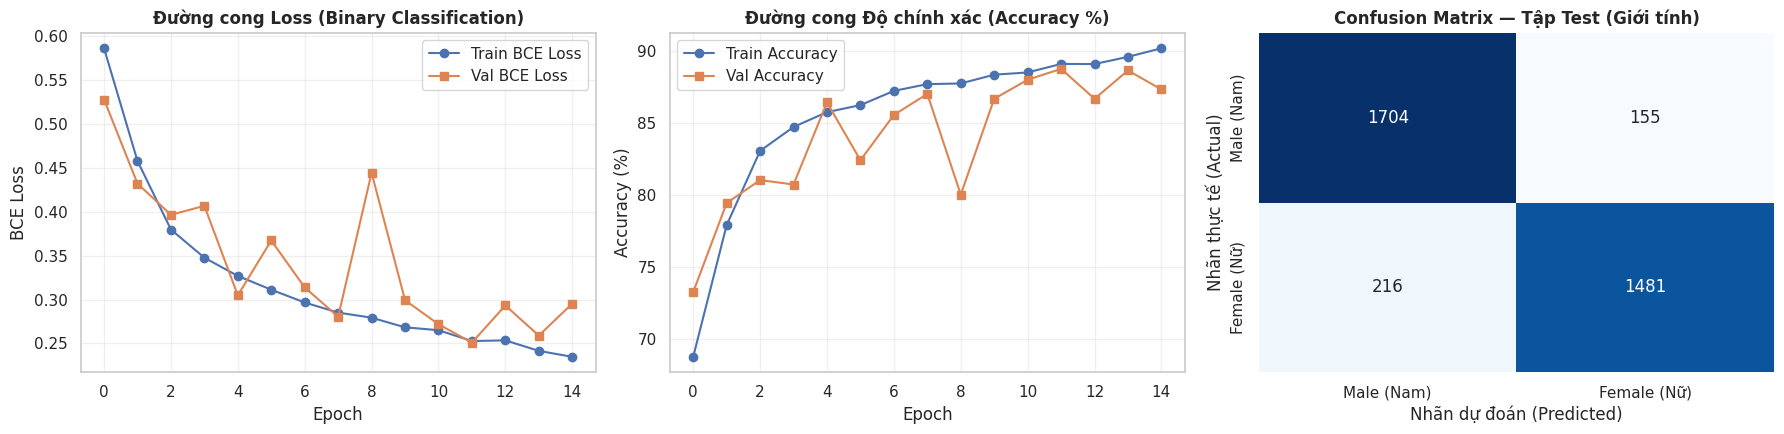

In [6]:
# Đánh giá trên tập Test
gender_model.eval()
y_true_gender, y_pred_gender, y_prob_gender = [], [], []

with torch.no_grad():
    for imgs, genders, _, _ in test_loader:
        imgs = imgs.to(device)
        logits = gender_model(imgs)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        y_prob_gender.extend(probs)
        y_pred_gender.extend(preds)
        y_true_gender.extend(genders.numpy().astype(int))

gender_test_acc = accuracy_score(y_true_gender, y_pred_gender)
gender_test_f1 = f1_score(y_true_gender, y_pred_gender, average="macro")

print("=" * 65)
print(f"KẾT QUẢ TẬP TEST — BINARY CLASSIFICATION (GENDER)")
print("=" * 65)
print(f"  • Test Accuracy : {gender_test_acc*100:.2f}%")
print(f"  • Macro F1-Score: {gender_test_f1*100:.2f}%")
print("\nBáo cáo chi tiết từng lớp:")
print(classification_report(y_true_gender, y_pred_gender, target_names=["Male (Nam)", "Female (Nữ)"], digits=4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Đường cong Loss
axes[0].plot(gender_history["train_loss"], marker="o", label="Train BCE Loss")
axes[0].plot(gender_history["val_loss"], marker="s", label="Val BCE Loss")
axes[0].set_title("Đường cong Loss (Binary Classification)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()

# 2. Đường cong Accuracy
axes[1].plot([a * 100 for a in gender_history["train_acc"]], marker="o", label="Train Accuracy")
axes[1].plot([a * 100 for a in gender_history["val_acc"]], marker="s", label="Val Accuracy")
axes[1].set_title("Đường cong Độ chính xác (Accuracy %)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

# 3. Confusion Matrix
cm_gender = confusion_matrix(y_true_gender, y_pred_gender)
sns.heatmap(
    cm_gender, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Male (Nam)", "Female (Nữ)"],
    yticklabels=["Male (Nam)", "Female (Nữ)"], ax=axes[2]
)
axes[2].set_title("Confusion Matrix — Tập Test (Giới tính)", fontweight="bold")
axes[2].set_xlabel("Nhãn dự đoán (Predicted)")
axes[2].set_ylabel("Nhãn thực tế (Actual)")

plt.tight_layout()
plt.show()

## 13. Thiết kế 5 Nơ-ron Output + `Softmax` + `Weighted CrossEntropyLoss`

- `race` gồm 5 nhóm định danh ngang hàng nhau (`0: White`, `1: Black`, `2: Asian`, `3: Indian`, `4: Others`).
- Vì dữ liệu mất cân bằng mạnh (`Imbalance Ratio = 5.96x`), ta truyền bộ trọng số lớp `race_class_weights_tensor = [0.470, 1.048, 1.381, 1.193, 2.802]` vào hàm `nn.CrossEntropyLoss(weight=race_class_weights_tensor)`:
  $$\mathcal{L}_{\text{Weighted-CE}}(y, z) = - w_y \cdot \log \left( \frac{e^{z_y}}{\sum_{j=0}^{4} e^{z_j}} \right)$$

In [7]:
race_model = MultiClassRaceCNN(num_classes=5, dropout_rate=0.3).to(device)
criterion_race = nn.CrossEntropyLoss(weight=race_class_weights_tensor)
optimizer_race = optim.AdamW(race_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler_race = optim.lr_scheduler.ReduceLROnPlateau(optimizer_race, mode="min", factor=0.5, patience=2)

def train_evaluate_multiclass_race(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_val_f1 = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, _, races, _ in tqdm(train_loader, desc=f"[Race] Epoch {epoch}/{epochs} [Train]", leave=False):
            imgs, races = imgs.to(device), races.to(device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, races)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == races).sum().item()
            total += imgs.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # --- VALIDATION ---
        model.eval()
        val_running_loss, val_total = 0.0, 0
        val_preds_all, val_targets_all = [], []
        with torch.no_grad():
            for imgs, _, races, _ in val_loader:
                imgs, races = imgs.to(device), races.to(device)
                logits = model(imgs)
                loss = criterion(logits, races)
                val_running_loss += loss.item() * imgs.size(0)
                val_total += imgs.size(0)
                val_preds_all.extend(logits.argmax(dim=1).cpu().numpy())
                val_targets_all.extend(races.cpu().numpy())

        val_loss = val_running_loss / val_total
        val_acc = accuracy_score(val_targets_all, val_preds_all)
        val_macro_f1 = f1_score(val_targets_all, val_preds_all, average="macro")
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_macro_f1)

        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1
            best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch:02d}/{epochs:02d} ({time.time()-t0:.1f}s) | "
              f"Train Loss: {train_loss:.4f} - Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}% - Macro F1: {val_macro_f1*100:.2f}%")

    model.load_state_dict(best_weights)
    return model, history

print("Bắt đầu huấn luyện Mô hình 2: MultiClassRaceCNN (với Balanced Class Weights)...")
race_model, race_history = train_evaluate_multiclass_race(
    race_model, train_loader, val_loader, criterion_race, optimizer_race, scheduler_race, EPOCHS_CUSTOM
)

Bắt đầu huấn luyện Mô hình 2: MultiClassRaceCNN (với Balanced Class Weights)...


[Race] Epoch 1/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 01/15 (67.4s) | Train Loss: 1.4626 - Acc: 40.46% | Val Loss: 1.3664 - Val Acc: 42.07% - Macro F1: 39.46%


[Race] Epoch 2/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 02/15 (66.4s) | Train Loss: 1.2673 - Acc: 52.61% | Val Loss: 1.2064 - Val Acc: 61.14% - Macro F1: 50.40%


...

Epoch 13/15 (68.4s) | Train Loss: 0.7111 - Acc: 75.48% | Val Loss: 0.9204 - Val Acc: 69.32% - Macro F1: 63.20%


[Race] Epoch 14/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 14/15 (67.9s) | Train Loss: 0.7017 - Acc: 75.69% | Val Loss: 0.8805 - Val Acc: 69.99% - Macro F1: 64.75%


[Race] Epoch 15/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 15/15 (67.8s) | Train Loss: 0.6501 - Acc: 76.92% | Val Loss: 0.7901 - Val Acc: 67.77% - Macro F1: 65.05%


## 14. Đánh giá `MultiClassRaceCNN` trên tập Test & Confusion Matrix 5×5

KẾT QUẢ TẬP TEST — MULTI-CLASS CLASSIFICATION (5 NHÓM RACE)
  • Test Accuracy       : 72.13%
  • Test Macro F1-Score : 65.01%

Báo cáo chi tiết từng nhóm Sắc tộc:
              precision    recall  f1-score   support

       White     0.7831    0.8690    0.8238      1512
       Black     0.8028    0.7673    0.7846       679
       Asian     0.8806    0.6155    0.7246       515
      Indian     0.7732    0.5034    0.6098       596
      Others     0.2349    0.4449    0.3075       254

    accuracy                         0.7213      3556
   macro avg     0.6949    0.6400    0.6501      3556
weighted avg     0.7601    0.7213    0.7292      3556



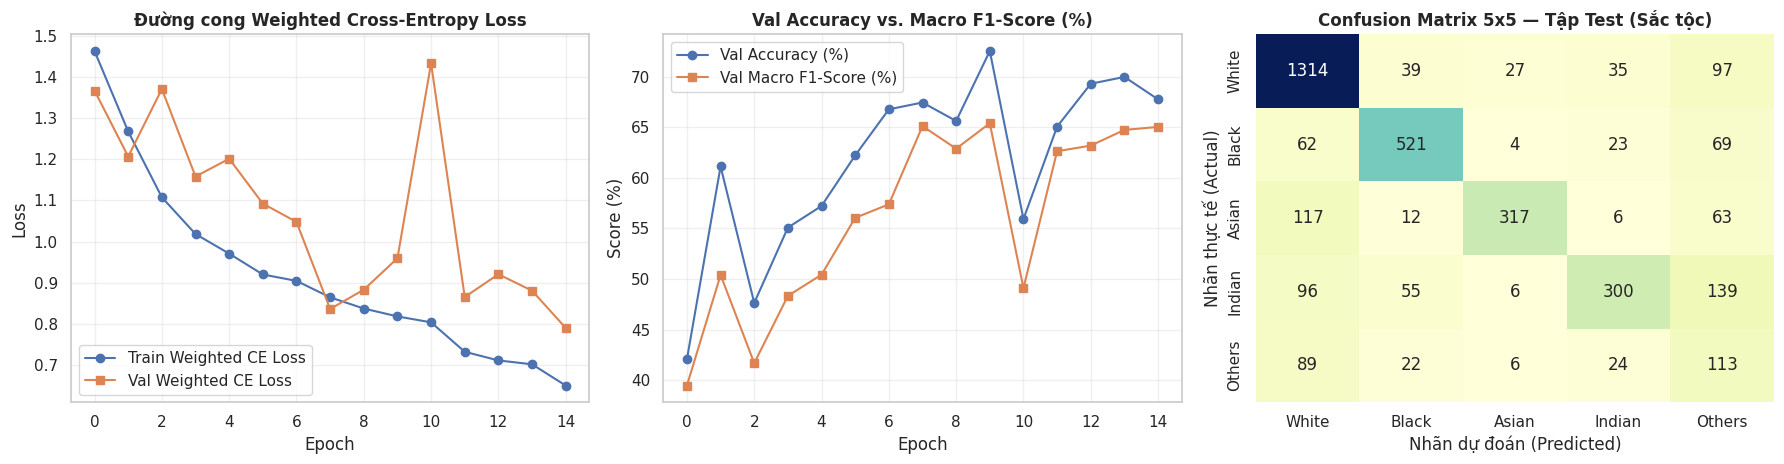

In [8]:
race_model.eval()
y_true_race, y_pred_race = [], []

with torch.no_grad():
    for imgs, _, races, _ in test_loader:
        imgs = imgs.to(device)
        logits = race_model(imgs)
        preds = logits.argmax(dim=1).cpu().numpy()
        y_pred_race.extend(preds)
        y_true_race.extend(races.numpy())

race_test_acc = accuracy_score(y_true_race, y_pred_race)
race_test_macro_f1 = f1_score(y_true_race, y_pred_race, average="macro")

print("=" * 65)
print("KẾT QUẢ TẬP TEST — MULTI-CLASS CLASSIFICATION (5 NHÓM RACE)")
print("=" * 65)
print(f"  • Test Accuracy       : {race_test_acc*100:.2f}%")
print(f"  • Test Macro F1-Score : {race_test_macro_f1*100:.2f}%")
print("\nBáo cáo chi tiết từng nhóm Sắc tộc:")
print(classification_report(y_true_race, y_pred_race, target_names=RACE_SHORT_NAMES, digits=4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(race_history["train_loss"], marker="o", label="Train Weighted CE Loss")
axes[0].plot(race_history["val_loss"], marker="s", label="Val Weighted CE Loss")
axes[0].set_title("Đường cong Weighted Cross-Entropy Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot([a * 100 for a in race_history["val_acc"]], marker="o", label="Val Accuracy (%)")
axes[1].plot([f * 100 for f in race_history["val_macro_f1"]], marker="s", label="Val Macro F1-Score (%)")
axes[1].set_title("Val Accuracy vs. Macro F1-Score (%)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (%)")
axes[1].legend()

cm_race = confusion_matrix(y_true_race, y_pred_race)
sns.heatmap(
    cm_race, annot=True, fmt="d", cmap="YlGnBu", cbar=False,
    xticklabels=RACE_SHORT_NAMES, yticklabels=RACE_SHORT_NAMES, ax=axes[2]
)
axes[2].set_title("Confusion Matrix 5x5 — Tập Test (Sắc tộc)", fontweight="bold")
axes[2].set_xlabel("Nhãn dự đoán (Predicted)")
axes[2].set_ylabel("Nhãn thực tế (Actual)")

plt.tight_layout()
plt.show()

## 15. Thiết lập `Huber Loss` & Huấn luyện `AgeRegressionCNN`

Từ biểu đồ EDA của biến `age`:
- Phân phối lệch phải (`Skewness = 0.622`) và có **`696` bức ảnh Outliers (`> 78.0` tuổi)**.
- Sử dụng `nn.SmoothL1Loss(beta=5.0)` giúp mô hình hội tụ êm ái khi sai số dưới `5` tuổi và phạt tuyến tính khi gặp các ảnh Outliers lệch lớn.

In [9]:
age_model = AgeRegressionCNN(dropout_rate=0.3).to(device)
criterion_age = nn.SmoothL1Loss(beta=5.0)
optimizer_age = optim.AdamW(age_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler_age = optim.lr_scheduler.ReduceLROnPlateau(optimizer_age, mode="min", factor=0.5, patience=2)

def train_evaluate_age_regression(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs):
    history = {"train_loss": [], "val_loss": [], "train_mae": [], "val_mae": []}
    best_val_mae = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        running_loss, running_abs_err, total = 0.0, 0.0, 0
        for imgs, _, _, ages in tqdm(train_loader, desc=f"[Age] Epoch {epoch}/{epochs} [Train]", leave=False):
            imgs, ages = imgs.to(device), ages.to(device)
            optimizer.zero_grad()
            preds = model(imgs)
            loss = criterion(preds, ages)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            running_abs_err += torch.abs(preds - ages).sum().item()
            total += imgs.size(0)

        train_loss = running_loss / total
        train_mae = running_abs_err / total

        # --- VALIDATION ---
        model.eval()
        val_running_loss, val_abs_err, val_total = 0.0, 0.0, 0
        with torch.no_grad():
            for imgs, _, _, ages in val_loader:
                imgs, ages = imgs.to(device), ages.to(device)
                preds = model(imgs)
                loss = criterion(preds, ages)
                val_running_loss += loss.item() * imgs.size(0)
                val_abs_err += torch.abs(preds - ages).sum().item()
                val_total += imgs.size(0)

        val_loss = val_running_loss / val_total
        val_mae = val_abs_err / val_total
        scheduler.step(val_mae)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_mae < best_val_mae:
            best_val_mae = val_mae
            best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch:02d}/{epochs:02d} ({time.time()-t0:.1f}s) | "
              f"Train Huber Loss: {train_loss:.4f} - MAE: {train_mae:.2f} năm | "
              f"Val Huber Loss: {val_loss:.4f} - Val MAE: {val_mae:.2f} năm")

    model.load_state_dict(best_weights)
    return model, history

print("Bắt đầu huấn luyện Mô hình 3: AgeRegressionCNN (với Huber / SmoothL1Loss)...")
age_model, age_history = train_evaluate_age_regression(
    age_model, train_loader, val_loader, criterion_age, optimizer_age, scheduler_age, EPOCHS_CUSTOM
)

Bắt đầu huấn luyện Mô hình 3: AgeRegressionCNN (với Huber / SmoothL1Loss)...


[Age] Epoch 1/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 01/15 (67.5s) | Train Huber Loss: 21.8645 - MAE: 24.22 năm | Val Huber Loss: 13.0044 - Val MAE: 15.26 năm


[Age] Epoch 2/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 02/15 (68.5s) | Train Huber Loss: 10.8414 - MAE: 13.11 năm | Val Huber Loss: 10.7291 - Val MAE: 13.00 năm


...

Epoch 13/15 (66.9s) | Train Huber Loss: 5.9048 - MAE: 8.00 năm | Val Huber Loss: 6.6153 - Val MAE: 8.75 năm


[Age] Epoch 14/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 14/15 (66.9s) | Train Huber Loss: 5.5506 - MAE: 7.62 năm | Val Huber Loss: 7.4089 - Val MAE: 9.56 năm


[Age] Epoch 15/15 [Train]:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 15/15 (67.8s) | Train Huber Loss: 5.4462 - MAE: 7.50 năm | Val Huber Loss: 5.3980 - Val MAE: 7.42 năm


## 16. Đánh giá `AgeRegressionCNN` trên tập Test (`MAE`, `RMSE`, $R^2$) & Biểu đồ Scatter Plot

KẾT QUẢ TẬP TEST — REGRESSION (DỰ ĐOÁN TUỔI)
  • Test MAE (Sai số tuyệt đối trung bình) : 7.53 năm tuổi
  • Test RMSE (Sai số toàn phương trung bình): 10.46 năm tuổi
  • Hệ số xác định R² (R-squared Score)    : 0.7261


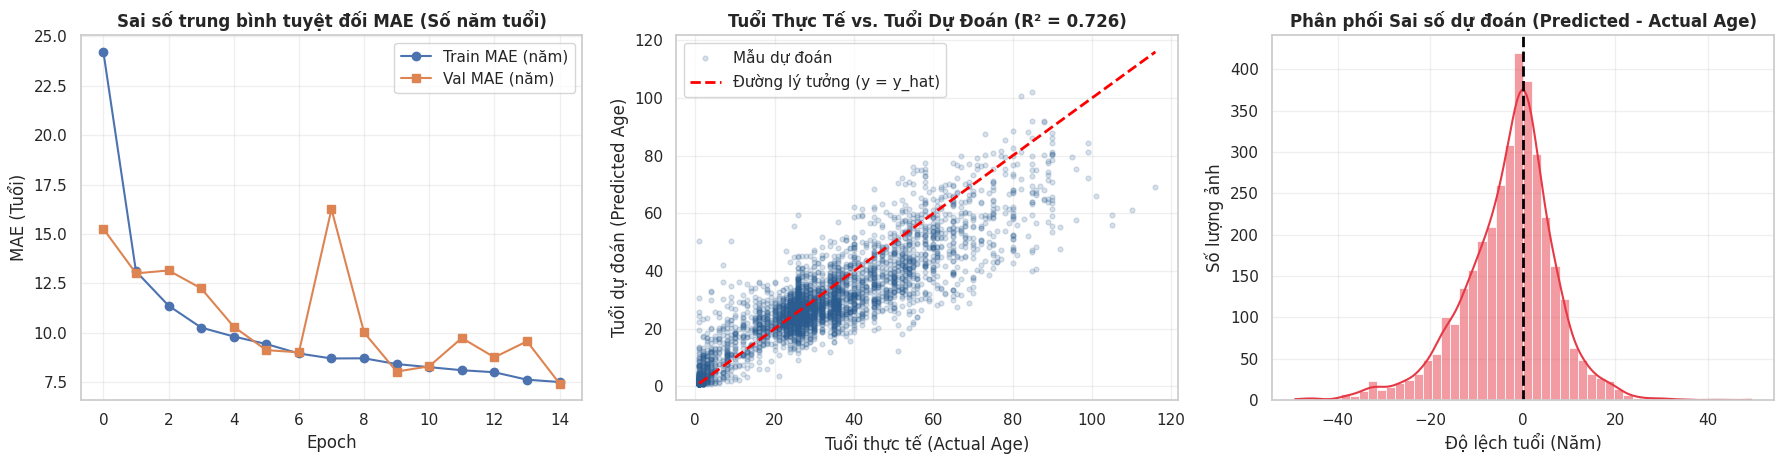

In [10]:
age_model.eval()
y_true_age, y_pred_age = [], []

with torch.no_grad():
    for imgs, _, _, ages in test_loader:
        imgs = imgs.to(device)
        # Khi suy luận thực tế, kẹp nhẹ miền hợp lệ [1.0, 116.0]
        preds = torch.clamp(age_model(imgs), min=1.0, max=116.0).cpu().numpy()
        y_pred_age.extend(preds)
        y_true_age.extend(ages.numpy())

y_true_age = np.array(y_true_age)
y_pred_age = np.array(y_pred_age)

age_test_mae = mean_absolute_error(y_true_age, y_pred_age)
age_test_rmse = np.sqrt(mean_squared_error(y_true_age, y_pred_age))
age_test_r2 = r2_score(y_true_age, y_pred_age)

print("=" * 65)
print("KẾT QUẢ TẬP TEST — REGRESSION (DỰ ĐOÁN TUỔI)")
print("=" * 65)
print(f"  • Test MAE (Sai số tuyệt đối trung bình) : {age_test_mae:.2f} năm tuổi")
print(f"  • Test RMSE (Sai số toàn phương trung bình): {age_test_rmse:.2f} năm tuổi")
print(f"  • Hệ số xác định R² (R-squared Score)    : {age_test_r2:.4f}")
print("=" * 65)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1. Đường cong MAE (năm)
axes[0].plot(age_history["train_mae"], marker="o", label="Train MAE (năm)")
axes[0].plot(age_history["val_mae"], marker="s", label="Val MAE (năm)")
axes[0].set_title("Sai số trung bình tuyệt đối MAE (Số năm tuổi)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MAE (Tuổi)")
axes[0].legend()

# 2. Scatter plot: Tuổi thực tế vs Tuổi dự đoán
axes[1].scatter(y_true_age, y_pred_age, alpha=0.18, s=12, color="#2b5c8f", label="Mẫu dự đoán")
axes[1].plot([1, 116], [1, 116], color="red", linestyle="--", linewidth=2, label="Đường lý tưởng (y = y_hat)")
axes[1].set_title(f"Tuổi Thực Tế vs. Tuổi Dự Đoán (R² = {age_test_r2:.3f})", fontweight="bold")
axes[1].set_xlabel("Tuổi thực tế (Actual Age)")
axes[1].set_ylabel("Tuổi dự đoán (Predicted Age)")
axes[1].legend()

# 3. Phân phối sai số dự đoán (Residual Error = y_pred - y_true)
residuals = y_pred_age - y_true_age
sns.histplot(residuals, bins=50, kde=True, color="#e63946", ax=axes[2])
axes[2].axvline(0, color="black", linestyle="--", linewidth=2)
axes[2].set_title("Phân phối Sai số dự đoán (Predicted - Actual Age)", fontweight="bold")
axes[2].set_xlabel("Độ lệch tuổi (Năm)")
axes[2].set_ylabel("Số lượng ảnh")

plt.tight_layout()
plt.show()

## 17. Kiến trúc Multi-Task ResNet

Thay vì phải huấn luyện và lưu trữ 3 mạng CNN riêng lẻ tốn gấp 3 lần bộ nhớ và thời gian suy luận, ta thiết kế **1 mạng Multi-Task Learning duy nhất** kết hợp **Transfer Learning (`ResNet-18`)**:
- **Shared Backbone (`ResNet-18`)**: Tận dụng các bộ lọc tích chập có kết nối tắt (**Skip Connection** $y = F(x) + x$) đã được tiền huấn luyện trên 1.2 triệu ảnh ImageNet, trích xuất ra vector đặc trưng `512` chiều.
- **3 Nhánh Đầu ra (Task-Specific Heads)**:
  1. `gender_head`: `Linear(512 -> 128) -> LeakyReLU -> Dropout -> Linear(128 -> 1)` (Binary Classification)
  2. `race_head`: `Linear(512 -> 128) -> LeakyReLU -> Dropout -> Linear(128 -> 5)` (Multi-class Classification)
  3. `age_head`: `Linear(512 -> 128) -> LeakyReLU -> Dropout -> Linear(128 -> 1)` (Regression)
- **Xử lý Loss Balancing**:
  - Để Loss của `age` có cùng độ lớn khoảng `0.1 - 1.0` như Cross-Entropy của `gender` và `race`, ta chuẩn hóa nhẹ biến tuổi bằng cách chia cho `100.0` khi tính `SmoothL1Loss` (tức $\tilde{y}_{\text{age}} = \frac{\text{age}}{100.0} \in [0.01, 1.16]$), và nhân với hệ số trọng số $\lambda_{\text{age}} = 10.0$:
    $$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{gender}} + \mathcal{L}_{\text{race}} + 10.0 \times \mathcal{L}_{\text{age\_scaled}}$$

In [11]:
class MultiTaskFaceResNet(nn.Module):
    def __init__(self, backbone_name="resnet18", pretrained=True, dropout_rate=0.3):
        super().__init__()
        if backbone_name == "resnet50":
            weights = models.ResNet50_Weights.DEFAULT if pretrained else None
            backbone = models.resnet50(weights=weights)
        else:
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            backbone = models.resnet18(weights=weights)

        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()  # Bỏ lớp FC 1000 lớp của ImageNet, giữ lại vector đặc trưng
        self.backbone = backbone

        # Nhánh 1: Binary Classification (Gender -> 1 logit)
        self.gender_head = nn.Sequential(
            nn.Linear(in_features, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 1)
        )

        # Nhánh 2: Multi-class Classification (Race -> 5 logits)
        self.race_head = nn.Sequential(
            nn.Linear(in_features, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 5)
        )

        # Nhánh 3: Regression (Age -> 1 giá trị thực)
        self.age_head = nn.Sequential(
            nn.Linear(in_features, 128, bias=False),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.01, inplace=True),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        shared_features = self.backbone(x)
        gender_logit = self.gender_head(shared_features).squeeze(-1)
        race_logits = self.race_head(shared_features)
        age_pred = self.age_head(shared_features).squeeze(-1)
        return gender_logit, race_logits, age_pred

BACKBONE_CHOICE = "resnet18"
EPOCHS_MULTITASK = 8

multitask_model = MultiTaskFaceResNet(backbone_name=BACKBONE_CHOICE, pretrained=True, dropout_rate=0.3).to(device)
mt_params = sum(p.numel() for p in multitask_model.parameters() if p.requires_grad)
print(f"Đã khởi tạo MultiTaskFaceResNet ({BACKBONE_CHOICE}) với {mt_params:,} tham số")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


Đã khởi tạo MultiTaskFaceResNet (resnet18) với 11,374,791 tham số


## 18. Huấn luyện & Đánh giá Mô hình `MultiTaskFaceResNet`

In [12]:
criterion_mt_gender = nn.BCEWithLogitsLoss()
criterion_mt_race = nn.CrossEntropyLoss(weight=race_class_weights_tensor)
criterion_mt_age = nn.SmoothL1Loss(beta=0.05)  # beta=0.05 trên thang tuổi chia 100 tương đương 5.0 năm tuổi

optimizer_mt = optim.AdamW(multitask_model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler_mt = optim.lr_scheduler.ReduceLROnPlateau(optimizer_mt, mode="min", factor=0.5, patience=2)

mt_history = {"train_loss": [], "val_loss": [], "val_gender_acc": [], "val_race_f1": [], "val_age_mae": []}
best_mt_val_loss = float("inf")
best_mt_weights = copy.deepcopy(multitask_model.state_dict())

print(f"Bắt đầu huấn luyện MultiTaskFaceResNet ({BACKBONE_CHOICE})...")
for epoch in range(1, EPOCHS_MULTITASK + 1):
    t0 = time.time()
    multitask_model.train()
    running_loss, total = 0.0, 0

    for imgs, genders, races, ages in tqdm(train_loader, desc=f"[Multi-Task] Epoch {epoch}/{EPOCHS_MULTITASK}", leave=False):
        imgs = imgs.to(device)
        genders = genders.to(device)
        races = races.to(device)
        ages_scaled = (ages / 100.0).to(device)

        optimizer_mt.zero_grad()
        g_logit, r_logits, a_pred_scaled = multitask_model(imgs)

        loss_g = criterion_mt_gender(g_logit, genders)
        loss_r = criterion_mt_race(r_logits, races)
        loss_a = criterion_mt_age(a_pred_scaled, ages_scaled)

        total_loss = loss_g + loss_r + 10.0 * loss_a
        total_loss.backward()
        optimizer_mt.step()

        running_loss += total_loss.item() * imgs.size(0)
        total += imgs.size(0)

    train_loss = running_loss / total

    # --- VALIDATION ---
    multitask_model.eval()
    val_running_loss, val_total = 0.0, 0
    val_g_preds, val_g_trues = [], []
    val_r_preds, val_r_trues = [], []
    val_a_abs_err = 0.0

    with torch.no_grad():
        for imgs, genders, races, ages in val_loader:
            imgs = imgs.to(device)
            genders = genders.to(device)
            races = races.to(device)
            ages_scaled = (ages / 100.0).to(device)

            g_logit, r_logits, a_pred_scaled = multitask_model(imgs)
            loss_g = criterion_mt_gender(g_logit, genders)
            loss_r = criterion_mt_race(r_logits, races)
            loss_a = criterion_mt_age(a_pred_scaled, ages_scaled)
            total_loss = loss_g + loss_r + 10.0 * loss_a

            val_running_loss += total_loss.item() * imgs.size(0)
            val_total += imgs.size(0)

            val_g_preds.extend((torch.sigmoid(g_logit) >= 0.5).cpu().numpy().astype(int))
            val_g_trues.extend(genders.cpu().numpy().astype(int))

            val_r_preds.extend(r_logits.argmax(dim=1).cpu().numpy())
            val_r_trues.extend(races.cpu().numpy())

            age_pred_years = a_pred_scaled.cpu() * 100.0
            val_a_abs_err += torch.abs(age_pred_years - ages).sum().item()

    val_loss = val_running_loss / val_total
    val_g_acc = accuracy_score(val_g_trues, val_g_preds)
    val_r_f1 = f1_score(val_r_trues, val_r_preds, average="macro")
    val_a_mae = val_a_abs_err / val_total
    scheduler_mt.step(val_loss)

    mt_history["train_loss"].append(train_loss)
    mt_history["val_loss"].append(val_loss)
    mt_history["val_gender_acc"].append(val_g_acc)
    mt_history["val_race_f1"].append(val_r_f1)
    mt_history["val_age_mae"].append(val_a_mae)

    if val_loss < best_mt_val_loss:
        best_mt_val_loss = val_loss
        best_mt_weights = copy.deepcopy(multitask_model.state_dict())

    print(f"Epoch {epoch:02d}/{EPOCHS_MULTITASK:02d} ({time.time()-t0:.1f}s) | "
          f"Val Loss: {val_loss:.4f} | Gender Acc: {val_g_acc*100:.2f}% | "
          f"Race Macro-F1: {val_r_f1*100:.2f}% | Age MAE: {val_a_mae:.2f} năm")

multitask_model.load_state_dict(best_mt_weights)

Bắt đầu huấn luyện MultiTaskFaceResNet (resnet18)...


[Multi-Task] Epoch 1/8:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 01/08 (73.1s) | Val Loss: 2.4251 | Gender Acc: 80.65% | Race Macro-F1: 60.66% | Age MAE: 11.96 năm


[Multi-Task] Epoch 2/8:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 02/08 (72.8s) | Val Loss: 1.6735 | Gender Acc: 88.58% | Race Macro-F1: 71.23% | Age MAE: 8.50 năm


...

[Multi-Task] Epoch 7/8:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 07/08 (73.1s) | Val Loss: 1.2441 | Gender Acc: 90.21% | Race Macro-F1: 74.78% | Age MAE: 5.69 năm


[Multi-Task] Epoch 8/8:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 08/08 (72.9s) | Val Loss: 1.2385 | Gender Acc: 93.08% | Race Macro-F1: 74.70% | Age MAE: 6.55 năm


<All keys matched successfully>

## 19. Đánh giá `MultiTaskFaceResNet` trên tập Test & So sánh với các mô hình Custom CNN

In [13]:
multitask_model.eval()
mt_g_preds, mt_g_trues = [], []
mt_r_preds, mt_r_trues = [], []
mt_a_preds, mt_a_trues = [], []

with torch.no_grad():
    for imgs, genders, races, ages in test_loader:
        imgs = imgs.to(device)
        g_logit, r_logits, a_pred_scaled = multitask_model(imgs)

        mt_g_preds.extend((torch.sigmoid(g_logit) >= 0.5).cpu().numpy().astype(int))
        mt_g_trues.extend(genders.numpy().astype(int))

        mt_r_preds.extend(r_logits.argmax(dim=1).cpu().numpy())
        mt_r_trues.extend(races.numpy())

        age_years = torch.clamp(a_pred_scaled * 100.0, min=1.0, max=116.0).cpu().numpy()
        mt_a_preds.extend(age_years)
        mt_a_trues.extend(ages.numpy())

mt_gender_acc = accuracy_score(mt_g_trues, mt_g_preds)
mt_gender_f1 = f1_score(mt_g_trues, mt_g_preds, average="macro")
mt_race_acc = accuracy_score(mt_r_trues, mt_r_preds)
mt_race_f1 = f1_score(mt_r_trues, mt_r_preds, average="macro")
mt_age_mae = mean_absolute_error(mt_a_trues, mt_a_preds)
mt_age_rmse = np.sqrt(mean_squared_error(mt_a_trues, mt_a_preds))
mt_age_r2 = r2_score(mt_a_trues, mt_a_preds)

comparison_df = pd.DataFrame([
    {
        "Mô hình": "1. Custom CNN (3 mô hình độc lập)",
        "Gender Test Acc (%)": round(gender_test_acc * 100, 2),
        "Gender Macro F1 (%)": round(gender_test_f1 * 100, 2),
        "Race Test Acc (%)": round(race_test_acc * 100, 2),
        "Race Macro F1 (%)": round(race_test_macro_f1 * 100, 2),
        "Age Test MAE (năm)": round(age_test_mae, 2),
        "Age Test RMSE (năm)": round(age_test_rmse, 2),
        "Age Test R²": round(age_test_r2, 4)
    },
    {
        "Mô hình": f"2. Multi-Task Transfer Learning ({BACKBONE_CHOICE})",
        "Gender Test Acc (%)": round(mt_gender_acc * 100, 2),
        "Gender Macro F1 (%)": round(mt_gender_f1 * 100, 2),
        "Race Test Acc (%)": round(mt_race_acc * 100, 2),
        "Race Macro F1 (%)": round(mt_race_f1 * 100, 2),
        "Age Test MAE (năm)": round(mt_age_mae, 2),
        "Age Test RMSE (năm)": round(mt_age_rmse, 2),
        "Age Test R²": round(mt_age_r2, 4)
    }
])

print("=" * 95)
print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TRÊN TẬP TEST (CUSTOM CNN vs. MULTI-TASK RESNET)")
print("=" * 95)
display(comparison_df)

BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TRÊN TẬP TEST (CUSTOM CNN vs. MULTI-TASK RESNET)


,Mô hình,Gender Test Acc (%),Gender Macro F1 (%),Race Test Acc (%),Race Macro F1 (%),Age Test MAE (năm),Age Test RMSE (năm),Age Test R²
0,1. Custom CNN (3 mô hình độc lập),89.57,89.53,72.13,65.01,7.53,10.46,0.7261
1,2. Multi-Task Transfer Learning (resnet18),92.15,92.15,78.26,73.52,5.49,7.67,0.8531


## 20. Trực quan hóa kết quả dự đoán trên 10 bức ảnh ngẫu nhiên của tập Test

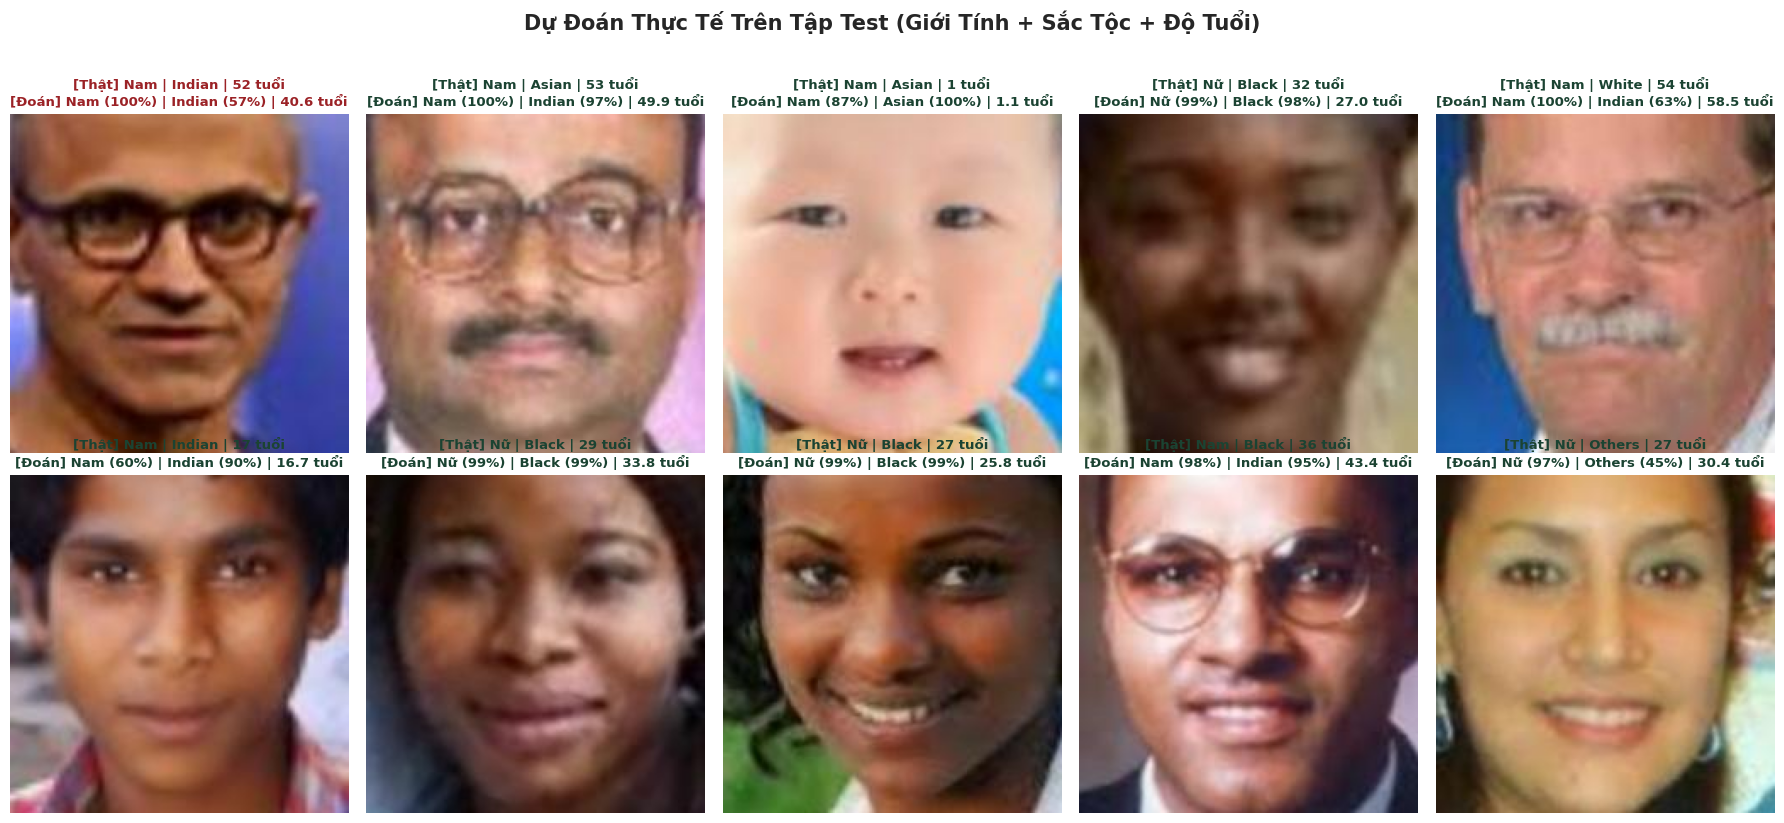

In [14]:
test_vis_df = test_df.sample(n=10, random_state=SEED).reset_index(drop=True)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

multitask_model.eval()
with torch.no_grad():
    for idx, ax in enumerate(axes.flat):
        row = test_vis_df.iloc[idx]
        with Image.open(row["filepath"]) as pil_img:
            rgb_img = pil_img.convert("RGB")
            ax.imshow(rgb_img)
            input_tensor = eval_transform(rgb_img).unsqueeze(0).to(device)

        g_logit, r_logits, a_pred_scaled = multitask_model(input_tensor)
        g_prob = torch.sigmoid(g_logit).item()
        pred_gender_idx = 1 if g_prob >= 0.5 else 0
        pred_gender_conf = g_prob if pred_gender_idx == 1 else (1.0 - g_prob)

        r_probs = torch.softmax(r_logits, dim=1).squeeze(0)
        pred_race_idx = int(r_probs.argmax().item())
        pred_race_conf = r_probs[pred_race_idx].item()

        pred_age = float(torch.clamp(a_pred_scaled * 100.0, min=1.0, max=116.0).item())

        true_g_str = "Nữ" if row["gender"] == 1 else "Nam"
        pred_g_str = "Nữ" if pred_gender_idx == 1 else "Nam"
        true_r_str = RACE_SHORT_NAMES[row["race"]]
        pred_r_str = RACE_SHORT_NAMES[pred_race_idx]

        title_color = "#1b4332" if (pred_gender_idx == row["gender"] and abs(pred_age - row["age"]) <= 8) else "#9b2226"
        ax.set_title(
            f"[Thật] {true_g_str} | {true_r_str} | {row['age']} tuổi\n"
            f"[Đoán] {pred_g_str} ({pred_gender_conf*100:.0f}%) | {pred_r_str} ({pred_race_conf*100:.0f}%) | {pred_age:.1f} tuổi",
            fontsize=9.5, color=title_color, fontweight="bold"
        )
        ax.axis("off")

plt.suptitle("Dự Đoán Thực Tế Trên Tập Test (Giới Tính + Sắc Tộc + Độ Tuổi)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 21. Thử nghiệm tương tác: Upload ảnh khuôn mặt bất kỳ từ máy tính của bạn lên Colab

Saving images (1).jpg to images (1).jpg


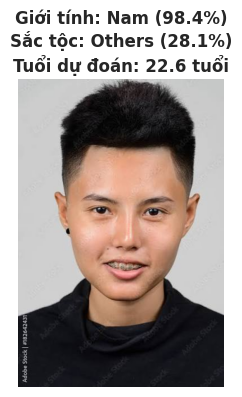

Hoàn tất toàn bộ quy trình từ EDA đến Huấn luyện & Đánh giá CNN!


In [17]:
# Tải ảnh khuôn mặt từ máy tính lên Colab để suy luận trực tiếp với mô hình Multi-Task ResNet-18
from google.colab import files
uploaded = files.upload()
for fn in uploaded.keys():
    with Image.open(fn) as user_img:
        rgb_user = user_img.convert("RGB")
        inp = eval_transform(rgb_user).unsqueeze(0).to(device)
        multitask_model.eval()
        with torch.no_grad():
            g_l, r_l, a_s = multitask_model(inp)
            g_p = torch.sigmoid(g_l).item()
            r_p = torch.softmax(r_l, dim=1).squeeze(0)
            r_idx = int(r_p.argmax().item())
            age_val = float(torch.clamp(a_s * 100.0, 1.0, 116.0).item())
        plt.figure(figsize=(4, 4))
        plt.imshow(rgb_user)
        plt.title(f"Giới tính: {'Nữ' if g_p>=0.5 else 'Nam'} ({max(g_p, 1-g_p)*100:.1f}%)\n"
                  f"Sắc tộc: {RACE_SHORT_NAMES[r_idx]} ({r_p[r_idx]*100:.1f}%)\n"
                  f"Tuổi dự đoán: {age_val:.1f} tuổi", fontweight="bold")
        plt.axis("off")
        plt.show()
print("Hoàn tất toàn bộ quy trình từ EDA đến Huấn luyện & Đánh giá CNN!")